In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Find project root
cwd = Path.cwd()

if (cwd / "data").is_dir() and (cwd / "outputs").is_dir():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data").is_dir() and (cwd.parent / "outputs").is_dir():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Cannot find the HAALSI_Project data/ and outputs/ folders."
    )

DATA = PROJECT_ROOT / "data"
OUTPUTS = PROJECT_ROOT / "outputs"

FIGURES = PROJECT_ROOT / "figures" / "supervisor"
FIGURES.mkdir(parents=True, exist_ok=True)

# Load datasets from data/ and results from outputs/
def load_csv(prefix):
    for folder in [DATA, OUTPUTS]:
        matches = sorted(
            folder.glob(f"{prefix}*.csv"),
            key=lambda p: p.stat().st_mtime,
            reverse=True
        )

        if matches:
            df = pd.read_csv(matches[0])
            print(
                f"Loaded [{folder.name}]: {matches[0].name} "
                f"({df.shape[0]:,} rows × {df.shape[1]} columns)"
            )
            return df

    print(f"Not found: {prefix}")
    return None


def get_col(df, *names):
    if df is None:
        return None

    lookup = {str(c).lower(): c for c in df.columns}

    for name in names:
        if name.lower() in lookup:
            return lookup[name.lower()]

    return None


def save_figure(name):
    plt.tight_layout()
    plt.savefig(
        FIGURES / f"{name}.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()


print("Project root:", PROJECT_ROOT)
print("Datasets in data/:", len(list(DATA.glob("*.csv"))))
print("Results in outputs/:", len(list(OUTPUTS.glob("*.csv"))))

Project root: c:\Users\kwane\Downloads\HAALSI_Project
Datasets in data/: 3
Results in outputs/: 95


In [2]:
primary = load_csv("section3_7_model_comparison")
controlled = load_csv("section3_8_model_summary")
ablation = load_csv("section3_4_ablation_performance")
shap = load_csv("section3_6_shap_importance")

primary_bootstrap = load_csv(
    "section3_7_paired_model_comparison_bootstrap"
)

education_bootstrap = load_csv(
    "section3_4_education_ablation_bootstrap"
)

for name, result in {
    "Primary comparison": primary,
    "Controlled comparison": controlled,
    "Education ablation": ablation,
    "SHAP": shap
}.items():
    print(f"\n{name}")
    if result is not None:
        display(result.head())
        print("Columns:", result.columns.tolist())

Loaded [outputs]: section3_7_model_comparison.csv (12 rows × 6 columns)
Loaded [outputs]: section3_8_model_summary.csv (16 rows × 5 columns)
Loaded [outputs]: section3_4_ablation_performance.csv (16 rows × 7 columns)
Loaded [outputs]: section3_6_shap_importance.csv (64 rows × 5 columns)
Loaded [outputs]: section3_7_paired_model_comparison_bootstrap.csv (6 rows × 7 columns)
Loaded [outputs]: section3_4_education_ablation_bootstrap.csv (40 rows × 8 columns)

Primary comparison


,Model,FeatureSet,MAE_mean,MAE_sd,RMSE_mean,R2_mean
0,RandomForest,A_Adjusted,1.204826,0.112507,1.546637,0.208644
1,RandomForest,A_AdjustedEducationBlind,1.228150,0.113841,1.565509,0.189268
2,RandomForest,A_TotalOnly,1.289740,0.097999,1.632902,0.119611
3,RandomForest,B_Adjusted,1.219890,0.108436,1.564384,0.190292
4,RandomForest,B_AdjustedEducationBlind,1.249934,0.105695,1.590541,0.162966


Columns: ['Model', 'FeatureSet', 'MAE_mean', 'MAE_sd', 'RMSE_mean', 'R2_mean']

Controlled comparison


,model,feature_set,mae,rmse,r2
0,MLP_LBFGS,A_TotalOnly,1.290725,1.632909,0.119122
1,MLP_LBFGS,B_DecomposedOnly,1.373169,1.757824,-0.021118
2,MLP_LBFGS,C_TotalAdjusted,1.904764,2.497153,-1.119842
3,MLP_LBFGS,D_DecomposedAdjusted,2.570705,3.367233,-2.796353
4,MLP_Original,A_TotalOnly,1.911487,2.262093,-1.035451


Columns: ['model', 'feature_set', 'mae', 'rmse', 'r2']

Education ablation


,Model,FeatureSet,EducationMode,MAE_mean,MAE_std,RMSE_mean,R2_mean
0,KAN,A_Conventional,WithEducation,1.172877,0.097977,1.507184,0.248296
1,KAN,A_Conventional,WithoutEducation,1.205954,0.095944,1.538397,0.217361
2,KAN,B_TotalRecall,WithEducation,1.166531,0.101579,1.490540,0.264236
3,KAN,B_TotalRecall,WithoutEducation,1.203250,0.101661,1.526957,0.228040
4,KAN,C_DecomposedSPC,WithEducation,1.165809,0.106847,1.490927,0.264660


Columns: ['Model', 'FeatureSet', 'EducationMode', 'MAE_mean', 'MAE_std', 'RMSE_mean', 'R2_mean']

SHAP


,Model,FeatureSet,Feature,MeanAbsSHAP,MeanSignedSHAP
0,KAN,B_TotalRecall,age_baseline,0.389925,0.039401
1,KAN,B_TotalRecall,education_level,0.287274,0.021384
2,KAN,B_TotalRecall,delayed_recall_baseline,0.275140,0.051347
3,KAN,B_TotalRecall,T_i_w1,0.243776,-0.058962
4,KAN,C_DecomposedSPC,age_baseline,0.332677,0.034895


Columns: ['Model', 'FeatureSet', 'Feature', 'MeanAbsSHAP', 'MeanSignedSHAP']


In [3]:
def plot_model_performance(df, title, filename):
    if df is None or df.empty:
        print(f"No data available for {title}")
        return

    required = ["Model", "FeatureSet", "MAE_mean"]
    missing = [c for c in required if c not in df.columns]

    if missing:
        print(f"Missing columns: {missing}")
        print("Available:", df.columns.tolist())
        return

    plot_df = df.copy()
    plot_df["MAE_mean"] = pd.to_numeric(
        plot_df["MAE_mean"], errors="coerce"
    )
    plot_df = plot_df.dropna(subset=["MAE_mean"])

    fig, ax = plt.subplots(figsize=(12, 6))

    sns.barplot(
        data=plot_df,
        x="Model",
        y="MAE_mean",
        hue="FeatureSet",
        errorbar=None,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Model")
    ax.set_ylabel("Mean absolute error (MAE)")
    ax.legend(title="Feature representation",
              bbox_to_anchor=(1.02, 1), loc="upper left")

    save_figure(filename)

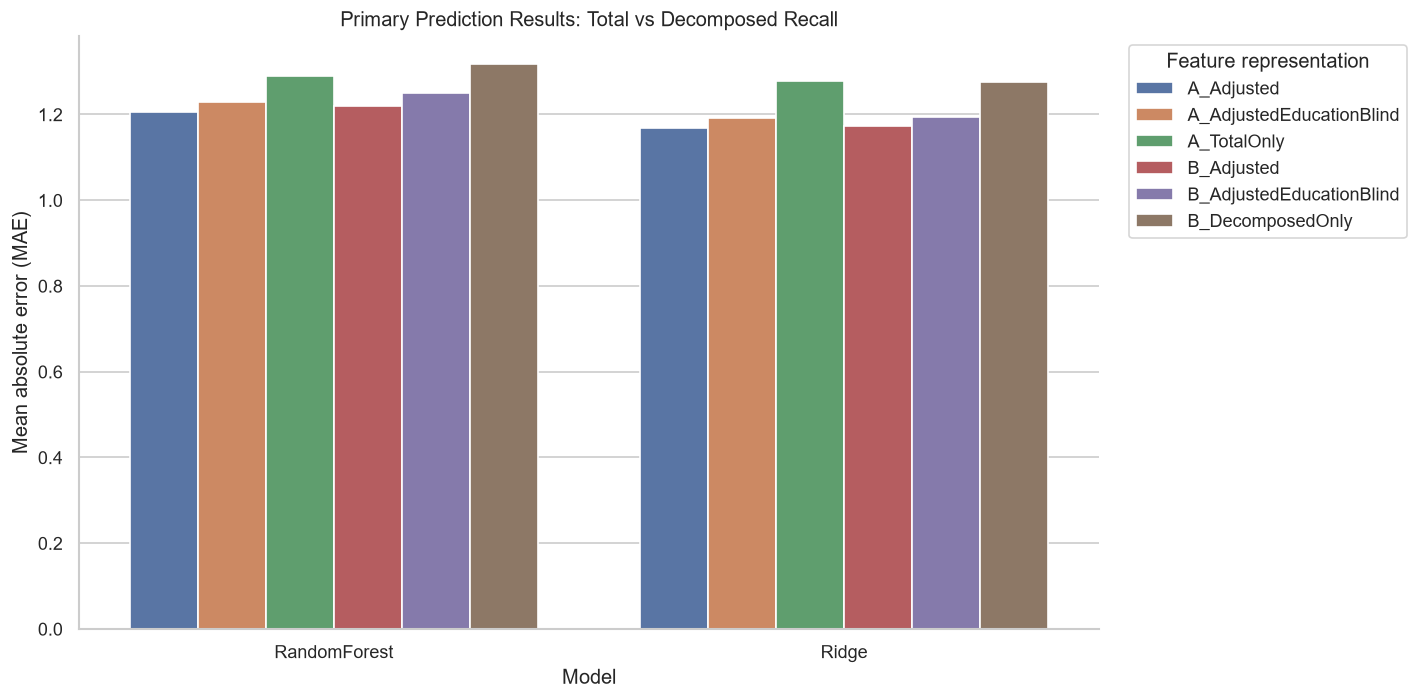

In [4]:
plot_model_performance(
    primary,
    "Primary Prediction Results: Total vs Decomposed Recall",
    "08_primary_model_comparison"
)

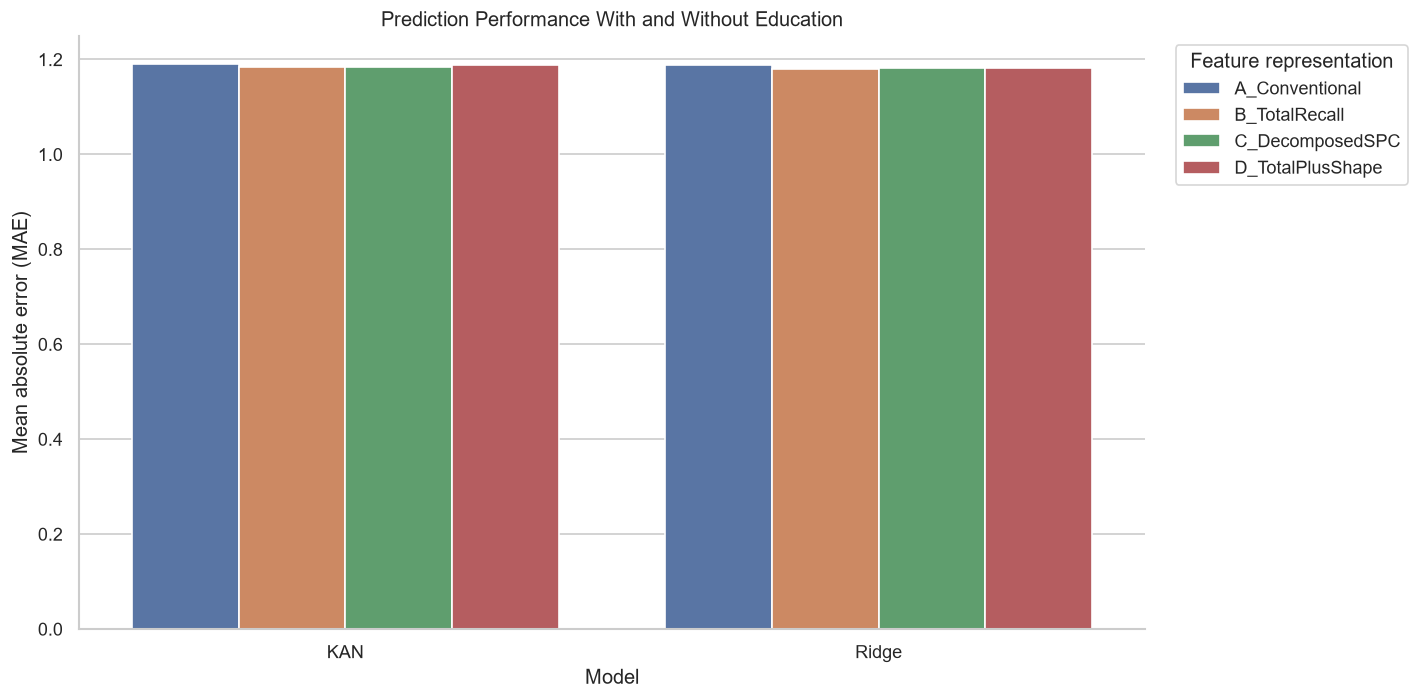

In [5]:
plot_model_performance(
    ablation,
    "Prediction Performance With and Without Education",
    "10_education_ablation"
)

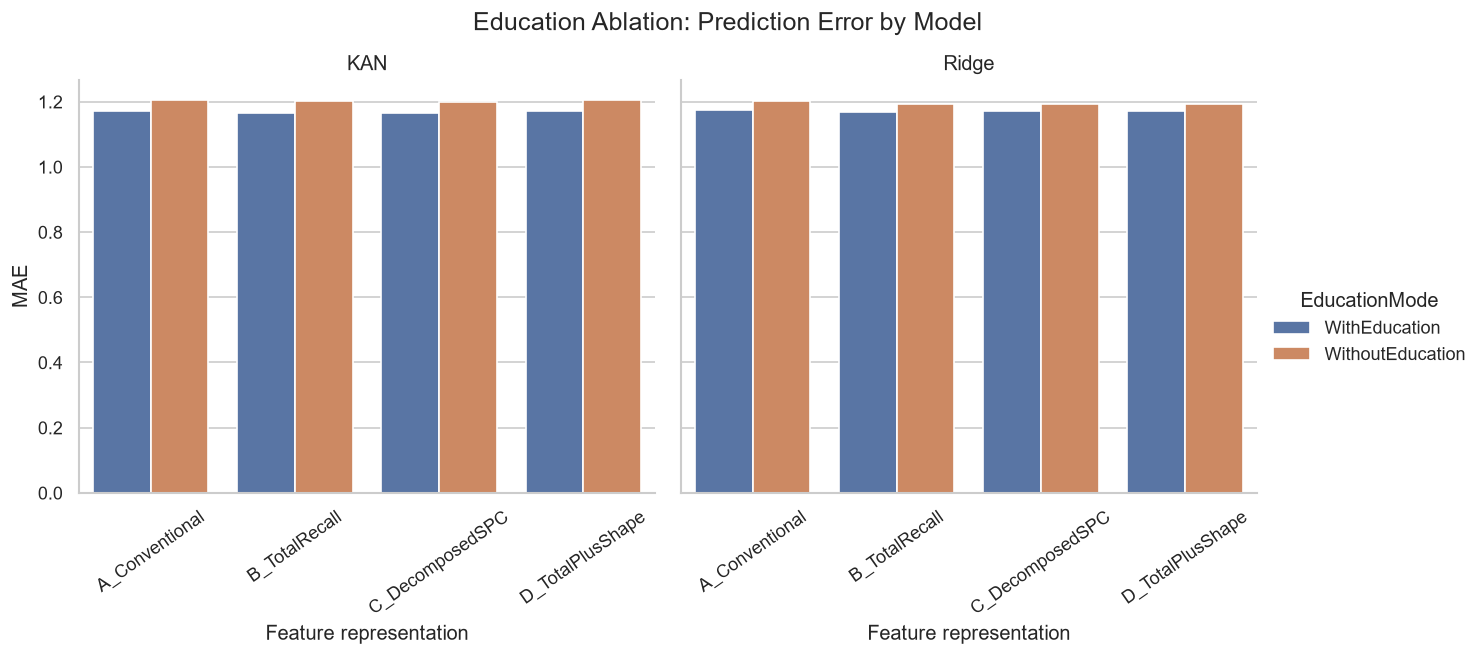

In [6]:
if ablation is not None:
    plot_df = ablation.copy()

    g = sns.catplot(
        data=plot_df,
        x="FeatureSet",
        y="MAE_mean",
        hue="EducationMode",
        col="Model",
        kind="bar",
        errorbar=None,
        col_wrap=2,
        height=4.5,
        aspect=1.2,
        sharey=True
    )

    g.set_axis_labels("Feature representation", "MAE")
    g.set_titles("{col_name}")

    for ax in g.axes.flat:
        ax.tick_params(axis="x", rotation=35)

    g.figure.suptitle(
        "Education Ablation: Prediction Error by Model",
        y=1.04,
        fontsize=15
    )

    g.figure.savefig(
        FIGURES / "10_education_ablation.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()

In [7]:
if primary_bootstrap is not None:
    print("Primary model comparison: bootstrap uncertainty")
    display(primary_bootstrap)

if education_bootstrap is not None:
    print("Education ablation: bootstrap uncertainty")
    display(education_bootstrap)

Primary model comparison: bootstrap uncertainty


,Model,Baseline,Proposed,N,Improvement_PositiveIsBetter,CI95_Lower,CI95_Upper
0,Ridge,A_TotalOnly,B_DecomposedOnly,504,0.001198,-0.005088,0.007309
1,Ridge,A_Adjusted,B_Adjusted,504,-0.003857,-0.005974,-0.001625
2,Ridge,A_AdjustedEducationBlind,B_AdjustedEducationBlind,504,-0.002291,-0.006275,0.001515
3,RandomForest,A_TotalOnly,B_DecomposedOnly,504,-0.027050,-0.048978,-0.003733
4,RandomForest,A_Adjusted,B_Adjusted,504,-0.015052,-0.033946,0.003523
5,RandomForest,A_AdjustedEducationBlind,B_AdjustedEducationBlind,504,-0.021753,-0.041053,-0.002271


Education ablation: bootstrap uncertainty


,Model,FeatureSet,Subgroup,N,Comparison,DeltaMAE_WithoutMinusWith,CI95_Lower,CI95_Upper
0,KAN,A_Conventional,All,504,Education ablation: without minus with,0.033067,0.009393,0.058436
1,KAN,A_Conventional,EducationCategory1,273,Education ablation: without minus with,0.013997,-0.016791,0.044615
2,KAN,A_Conventional,EducationCategory2,171,Education ablation: without minus with,0.031082,0.002737,0.061448
3,KAN,A_Conventional,EducationCategory3,35,Education ablation: without minus with,0.151458,-0.006695,0.309497
4,KAN,A_Conventional,EducationCategory4,25,Education ablation: without minus with,0.089145,-0.078618,0.246125
5,KAN,B_TotalRecall,All,504,Education ablation: without minus with,0.036685,0.014141,0.059318
6,KAN,B_TotalRecall,EducationCategory1,273,Education ablation: without minus with,0.018117,-0.011602,0.047822
7,KAN,B_TotalRecall,EducationCategory2,171,Education ablation: without minus with,0.036018,0.008655,0.064823
8,KAN,B_TotalRecall,EducationCategory3,35,Education ablation: without minus with,0.118831,-0.026455,0.262996
9,KAN,B_TotalRecall,EducationCategory4,25,Education ablation: without minus with,0.128996,-0.030355,0.289206


SHAP columns: ['Model', 'FeatureSet', 'Feature', 'MeanAbsSHAP', 'MeanSignedSHAP']


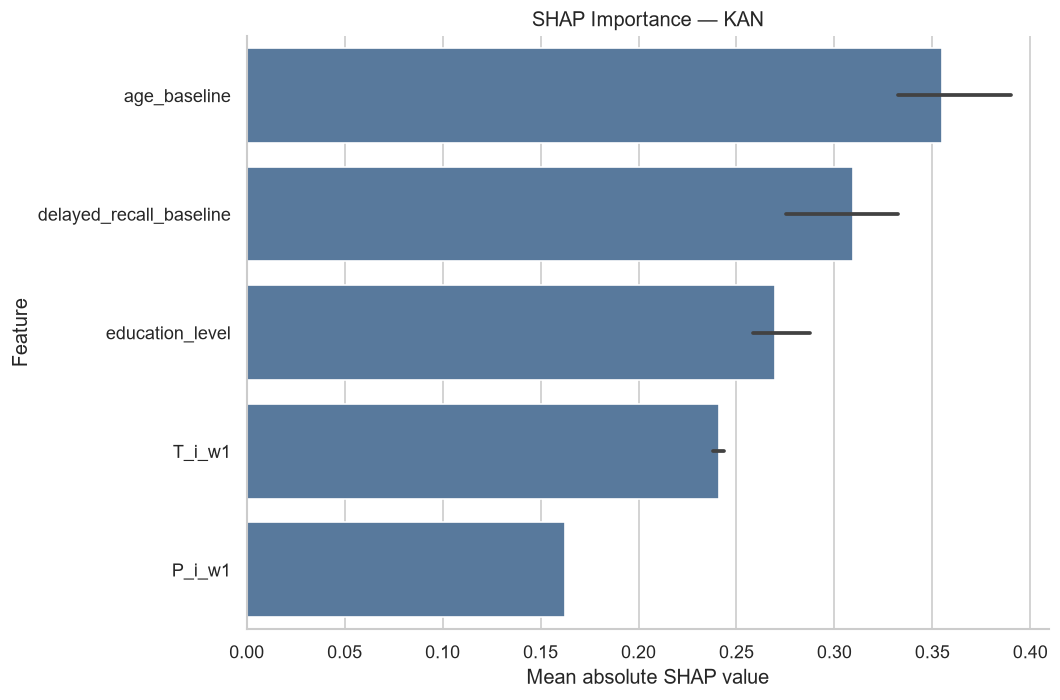

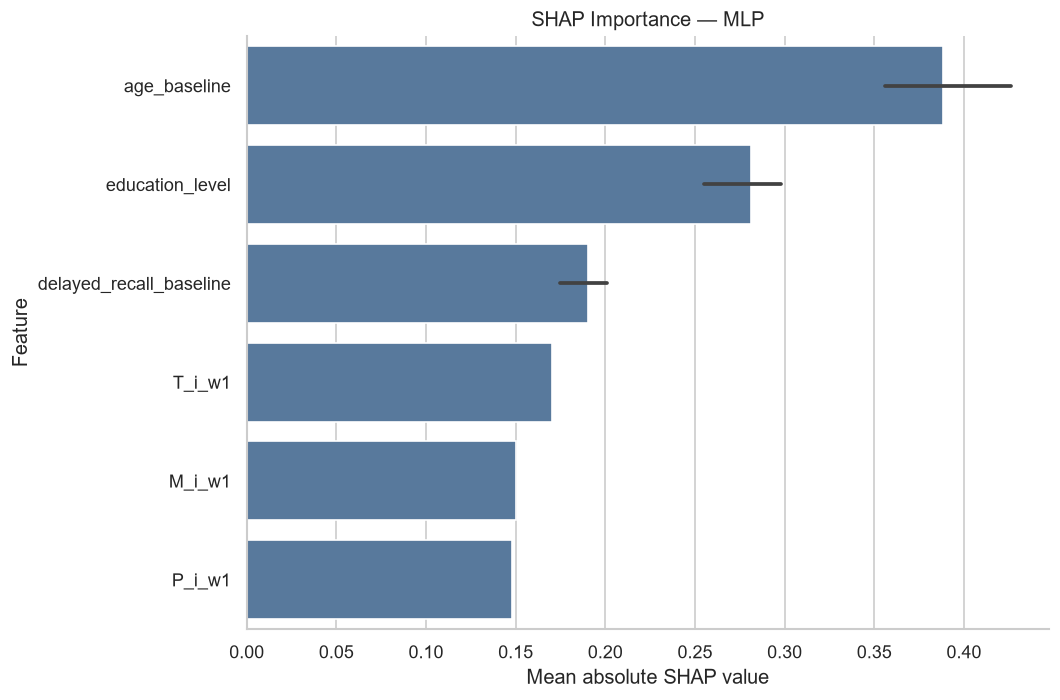

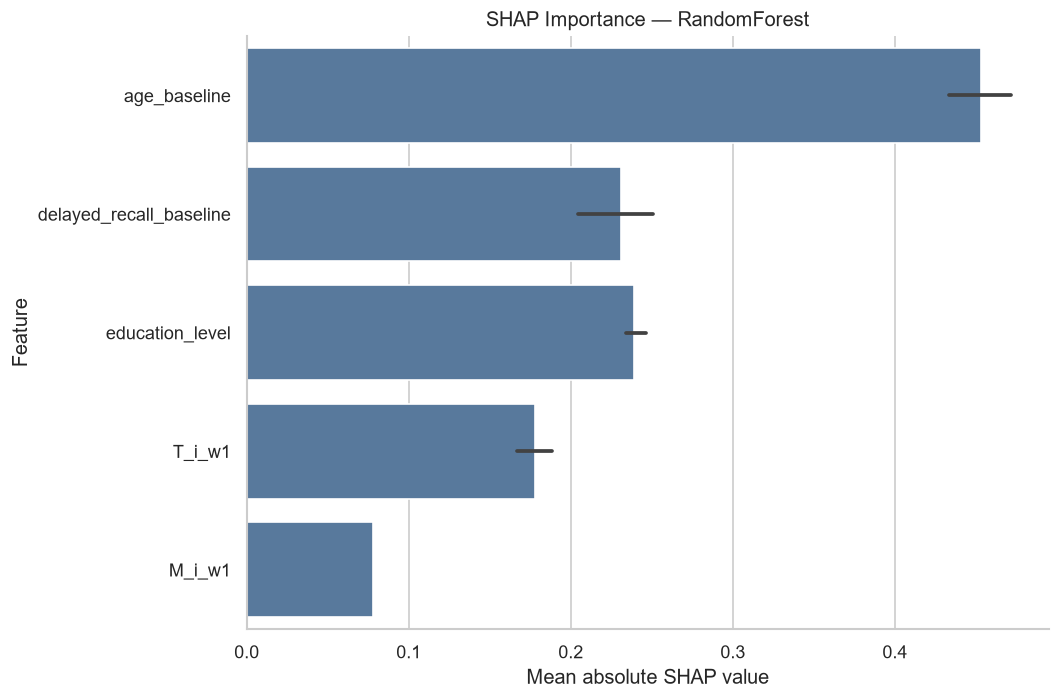

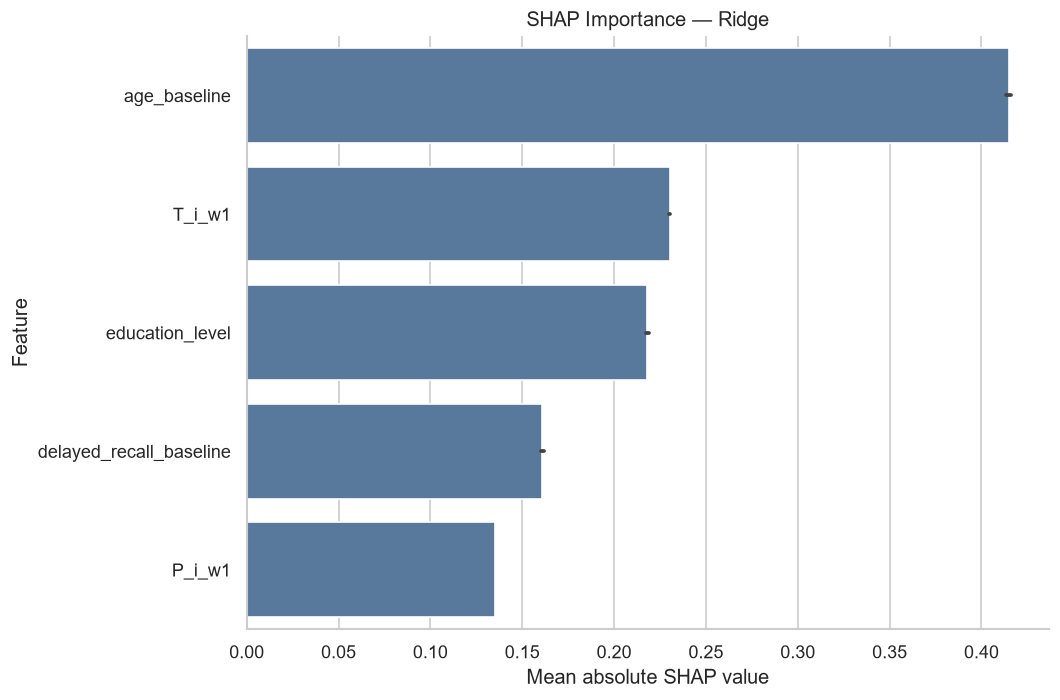

In [8]:
if shap is not None:
    print("SHAP columns:", shap.columns.tolist())

    def match_column(df, candidates):
        normalized = {
            str(c).lower().replace("_", "").replace(" ", ""): c
            for c in df.columns
        }
        for candidate in candidates:
            key = candidate.lower().replace("_", "").replace(" ", "")
            if key in normalized:
                return normalized[key]
        return None

    feature_col = match_column(shap, [
        "Feature", "FeatureName", "Variable"
    ])
    value_col = match_column(shap, [
        "MeanAbsSHAP", "MeanAbsoluteSHAP",
        "MeanSHAP", "SHAPImportance",
        "Importance", "MeanAbsSHAPValue"
    ])
    model_col = match_column(shap, [
        "Model", "ModelName"
    ])

    if feature_col and value_col:
        shap_plot = shap.copy()
        shap_plot[value_col] = pd.to_numeric(
            shap_plot[value_col], errors="coerce"
        )

        models = (
            shap_plot[model_col].dropna().unique()
            if model_col else ["All"]
        )

        for model in models:
            subset = (
                shap_plot[shap_plot[model_col] == model]
                if model_col else shap_plot
            )

            subset = subset.nlargest(12, value_col)

            fig, ax = plt.subplots(figsize=(9, 6))
            sns.barplot(
                data=subset,
                x=value_col,
                y=feature_col,
                color="#4C78A8",
                ax=ax
            )

            ax.set_title(f"SHAP Importance — {model}")
            ax.set_xlabel("Mean absolute SHAP value")
            ax.set_ylabel("Feature")

            safe_name = str(model).replace(" ", "_")
            save_figure(f"11_shap_{safe_name}")
    else:
        print("Unrecognised SHAP columns:")
        print(shap.columns.tolist())

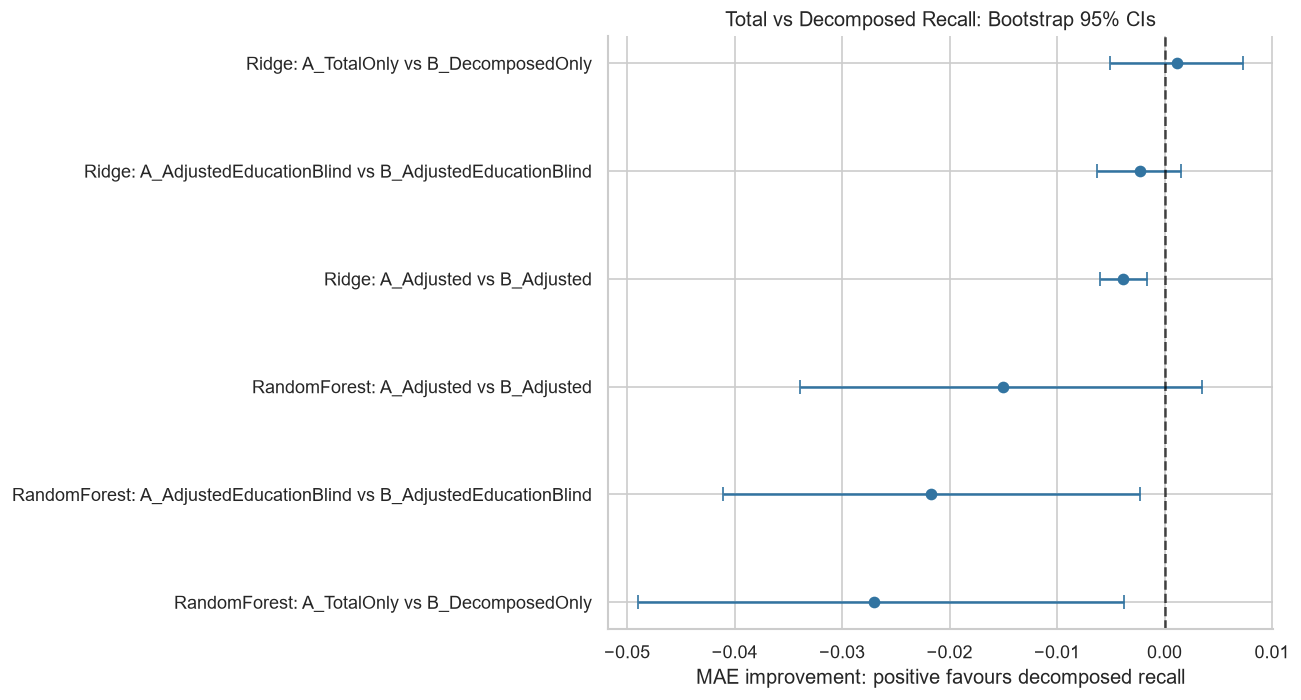

In [9]:
if primary_bootstrap is not None:
    boot = primary_bootstrap.copy()

    boot["Comparison"] = (
        boot["Model"] + ": "
        + boot["Baseline"] + " vs "
        + boot["Proposed"]
    )

    boot = boot.sort_values("Improvement_PositiveIsBetter")

    y = np.arange(len(boot))
    estimates = boot["Improvement_PositiveIsBetter"].to_numpy()
    lower = boot["CI95_Lower"].to_numpy()
    upper = boot["CI95_Upper"].to_numpy()

    fig, ax = plt.subplots(figsize=(11, 6))

    ax.errorbar(
        estimates,
        y,
        xerr=[estimates - lower, upper - estimates],
        fmt="o",
        capsize=4,
        color="#3274A1"
    )

    ax.axvline(0, color="black", linestyle="--", alpha=0.7)
    ax.set_yticks(y)
    ax.set_yticklabels(boot["Comparison"])
    ax.set_xlabel(
        "MAE improvement: positive favours decomposed recall"
    )
    ax.set_title(
        "Total vs Decomposed Recall: Bootstrap 95% CIs"
    )

    save_figure("12_primary_bootstrap_comparison")